# Hypothesis testing for particle physics: a hands-on tour

Every example uses a situation you meet in an experiment: calibration runs, test beams, efficiency measurements,
data/MC comparisons, fits to mass spectra, counting experiments and discovery significance.

| Section | Test | Typical particle-physics use |
|---|---|---|
| 1 | Student t-tests | calibration constants, module-to-module comparisons, before/after a detector change |
| 2 | χ² tests | histogram vs model, fit quality, channel/period consistency |
| 3 | Kolmogorov–Smirnov | pulls, unbinned data vs MC shapes, p-value calibration |
| 4 | Wald–Wolfowitz runs | fit residuals, data-quality monitoring |
| 5 | F-test | resolution comparison, choosing the degree of a background polynomial |
| 6 | Bayesian testing | efficiencies, counting experiments, Bayes factors vs p-values |
| 7 | Look-elsewhere effect | local vs global significance (toy MC) |

For each test: state $H_0$, build the statistic by hand, get the p-value, cross-check with `scipy.stats`, interpret.

> **HEP conventions.** Significance is quoted as $Z$ with $p = 1-\Phi(Z)$ (one-sided): 3σ ↔ $p=1.35\times10^{-3}$ ("evidence"),
> 5σ ↔ $p=2.87\times10^{-7}$ ("discovery"). The p-value is $P(\text{data this extreme}\mid H_0)$, **not** $P(H_0\mid\text{data})$.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, special, optimize

rng = np.random.default_rng(1234)   # fixed seed -> reproducible
ALPHA = 0.05

#stats.norm.isf(p) - Inverse Survival Function: It returns the value x such that the upper-tail probability P(X > x) = p
def p_to_Z(p): return stats.norm.isf(p)       # one-sided convention used in HEP
#stats.norm.sf(p) - Survival Function: probability that p: P(X > p) ==> t computes the upper-tail probability P(X > x), which equals 1 - cdf(x), often with greater numerical accuracy in extreme tails than 1 - stats.norm.cdf(x)
def Z_to_p(Z): return stats.norm.sf(Z)

def verdict(p, alpha=ALPHA):
    return f"p = {p:.4g} -> " + ("reject H0" if p < alpha else "cannot reject H0") + f" at alpha = {alpha}"

print("Z   one-sided p")
for Z in [1, 2, 3, 4, 5]:
    print(f"{Z}   {Z_to_p(Z):.3e}")

Z   one-sided p
1   1.587e-01
2   2.275e-02
3   1.350e-03
4   3.167e-05
5   2.867e-07


---
# **1. Student's t-tests**

With millions of events, a mean is effectively Gaussian and one uses a $z$-test. The t-test matters when the
sample is **small and the spread is estimated from the same sample**: a handful of calibration runs, test-beam
settings, chambers, pseudo-experiments.

## **1a. One-sample t-test: is my measurement compatible with the reference value?**
$$t=\frac{\bar x-\mu_0}{s/\sqrt n}\sim t_{n-1}\quad\text{under }H_0$$

# **Example:** 12 independent determinations of the Z mass (e.g. from 12 calibration data sets), each with an uncorrected scale shift of +0.18 GeV. $H_0$: $m_Z = 91.1876$ GeV.

In [3]:
mZ_pdg = 91.1876
mZ = rng.normal(mZ_pdg + 0.18, 0.25, size=12)      # GeV

n = len(mZ)
xbar, s = mZ.mean(), mZ.std(ddof=1)
t_stat = (xbar - mZ_pdg) / (s / np.sqrt(n))
p_val = 2 * stats.t.sf(abs(t_stat), n - 1)
tcrit = stats.t.ppf(1 - ALPHA / 2, n - 1)
ci = (xbar - tcrit * s / np.sqrt(n), xbar + tcrit * s / np.sqrt(n))

print(f"mean = {xbar:.3f} GeV, std = {s:.3f} GeV")
print(f"manual: t = {t_stat:.3f}, {verdict(p_val)}")
print(f"95% CI for the mean: [{ci[0]:.3f}, {ci[1]:.3f}] GeV (does it contain {mZ_pdg}?)")
print("scipy :", stats.ttest_1samp(mZ, mZ_pdg))

mean = 91.411 GeV, std = 0.337 GeV
manual: t = 2.296, p = 0.04234 -> reject H0 at alpha = 0.05
95% CI for the mean: [91.197, 91.625] GeV (does it contain 91.1876?)
scipy : TtestResult(statistic=np.float64(2.2958768897878232), pvalue=np.float64(0.04233788004172031), df=np.int64(11))


## **1b. Two-sample t-test (independent samples)**
Student (pooled variance) assumes equal variances; **Welch** does not and is the safe default.

* **Student** (pooled): assumes equal variances, $t=\dfrac{\bar x_1-\bar x_2}{s_p\sqrt{1/n_1+1/n_2}}$, dof $=n_1+n_2-2$.
* **Welch**: does *not* assume equal variances, $t=\dfrac{\bar x_1-\bar x_2}{\sqrt{s_1^2/n_1+s_2^2/n_2}}$, with Welch–Satterthwaite dof.


# **Example:** energy response $E_\text{meas}/E_\text{beam}$ measured in test-beam runs for two calorimeter modules.

In [4]:
modA = rng.normal(0.985, 0.010, size=18)     # 18 runs, good resolution
modB = rng.normal(1.012, 0.020, size=12)     # 12 runs, worse resolution
n1, n2 = len(modA), len(modB)
v1, v2 = modA.var(ddof=1), modB.var(ddof=1)

# Welch by hand
t_w = (modA.mean() - modB.mean()) / np.sqrt(v1 / n1 + v2 / n2)
dof_w = (v1 / n1 + v2 / n2) ** 2 / ((v1 / n1) ** 2 / (n1 - 1) + (v2 / n2) ** 2 / (n2 - 1))
print(f"Welch   manual: t = {t_w:.3f}, dof = {dof_w:.1f}, {verdict(2*stats.t.sf(abs(t_w), dof_w))}")
print("Welch   scipy :", stats.ttest_ind(modA, modB, equal_var=False))

# Student pooled by hand
sp2 = ((n1 - 1) * v1 + (n2 - 1) * v2) / (n1 + n2 - 2)
t_s = (modA.mean() - modB.mean()) / np.sqrt(sp2 * (1 / n1 + 1 / n2))
print(f"Student manual: t = {t_s:.3f}, dof = {n1+n2-2}, {verdict(2*stats.t.sf(abs(t_s), n1+n2-2))}")
print("Student scipy :", stats.ttest_ind(modA, modB, equal_var=True))

Welch   manual: t = -2.188, dof = 14.0, p = 0.04607 -> reject H0 at alpha = 0.05
Welch   scipy : TtestResult(statistic=np.float64(-2.1879916987324277), pvalue=np.float64(0.04606506353181635), df=np.float64(14.047045423916462))
Student manual: t = -2.512, dof = 28, p = 0.01805 -> reject H0 at alpha = 0.05
Student scipy : TtestResult(statistic=np.float64(-2.5119894326144054), pvalue=np.float64(0.018046761083514006), df=np.float64(28.0))


## **1c. Paired t-test**
Same objects, measured twice: use the differences $d_i$, then a one-sample test with $\mu_0=0$.

# **Example:** efficiency (%) of 14 muon chambers before and after raising the operating voltage. Chambers differ by a few percent among themselves, but the change per chamber is small and consistent.

In [5]:
nominal = rng.normal(94, 3, size=14)                          # chamber-to-chamber spread: 3 %
before = nominal + rng.normal(0, 0.25, size=14)               # measurement noise 0.25 %
after  = nominal + 0.6 + rng.normal(0, 0.25, size=14)         # true gain of 0.6 %

d = after - before
t_p = d.mean() / (d.std(ddof=1) / np.sqrt(len(d)))
print(f"paired manual: t = {t_p:.3f}, {verdict(2*stats.t.sf(abs(t_p), len(d)-1))}")
print("paired scipy :", stats.ttest_rel(after, before))
print("\nWRONG: ignoring the pairing ->", stats.ttest_ind(after, before, equal_var=False))

paired manual: t = 5.337, p = 0.000135 -> reject H0 at alpha = 0.05
paired scipy : TtestResult(statistic=np.float64(5.336746421959251), pvalue=np.float64(0.00013503755510347695), df=np.int64(13))

WRONG: ignoring the pairing -> TtestResult(statistic=np.float64(0.4926997019791159), pvalue=np.float64(0.6263764241080655), df=np.float64(25.8969222037314))


The unpaired test is swamped by chamber-to-chamber variation. Choose the test from the **design of the measurement**.

---
# **2. χ² tests**

## **2a. Goodness of fit of a histogram**
Counts per bin are **Poisson**. For large expected counts, Pearson's statistic is $\chi^2_\text{P}\sim\chi^2_\nu$:

$$\chi^2_\text{P}=\sum_i\frac{(O_i-E_i)^2}{E_i},\qquad \nu=N_\text{bins}-N_\text{fitted parameters}$$

For low counts use the **likelihood-ratio ("Baker–Cousins") χ²**, which comes directly from the Poisson likelihood:

$$\chi^2_\lambda = 2\sum_i\Big[E_i-O_i+O_i\ln\frac{O_i}{E_i}\Big]$$

# **Example:** a falling $p_T$ spectrum (20–200 GeV, 5 GeV bins) with only a few events per bin in the tail. We fit an exponential (2 parameters, Poisson likelihood) and test the fit quality.

fit: N = 4994, lambda = 34.41 GeV   (true (5000, 35.0))
Pearson chi2    = 44.16 for 34 dof -> p = 0.114
Likelihood-ratio = 46.69 for 34 dof -> p = 0.072
chi2/ndf = 1.30   (should be ~1 for a good fit; its spread is sqrt(2/ndf) = 0.24)


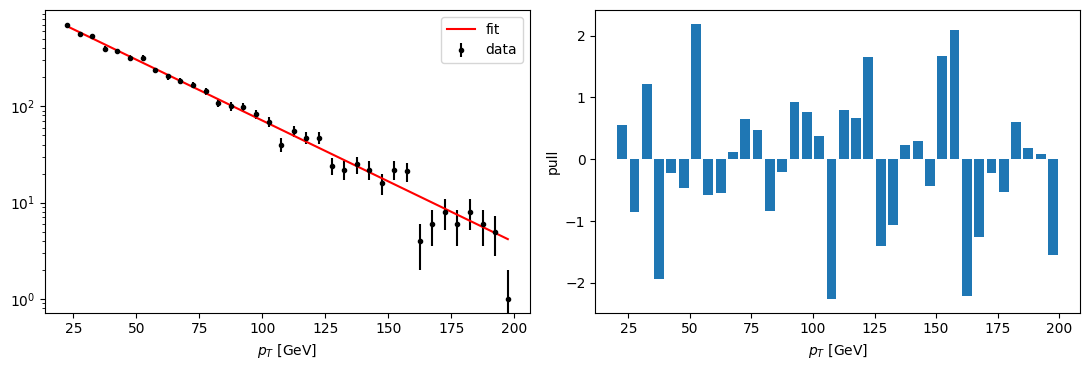

In [6]:
edges = np.arange(20, 205, 5.0)
ctr = 0.5 * (edges[1:] + edges[:-1])
nb = len(ctr)

def model(par, x):
    N, lam = par
    return N * 5.0 / lam * np.exp(-(x - 20) / lam)

def pearson(O, E):   return np.sum((O - E) ** 2 / E)
def lr_chi2(O, E):   return 2 * np.sum(E - O + special.xlogy(O, O / E))   # xlogy(0, .) = 0

true_par = (5000, 35.0)
obs = rng.poisson(model(true_par, ctr))

# Poisson-likelihood fit (maximum likelihood)
nll = lambda par: np.sum(model(par, ctr) - obs * np.log(model(par, ctr)))
fit = optimize.minimize(nll, x0=(obs.sum(), 30.0), method="Nelder-Mead")
E = model(fit.x, ctr)
nu = nb - 2

print(f"fit: N = {fit.x[0]:.0f}, lambda = {fit.x[1]:.2f} GeV   (true {true_par})")
print(f"Pearson chi2    = {pearson(obs, E):.2f} for {nu} dof -> p = {stats.chi2.sf(pearson(obs, E), nu):.3f}")
print(f"Likelihood-ratio = {lr_chi2(obs, E):.2f} for {nu} dof -> p = {stats.chi2.sf(lr_chi2(obs, E), nu):.3f}")
print(f"chi2/ndf = {pearson(obs, E)/nu:.2f}   (should be ~1 for a good fit; its spread is sqrt(2/ndf) = {np.sqrt(2/nu):.2f})")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].errorbar(ctr, obs, np.sqrt(obs), fmt="ko", ms=3, label="data")
ax[0].plot(ctr, E, "r", label="fit"); ax[0].set_yscale("log"); ax[0].set_xlabel("$p_T$ [GeV]"); ax[0].legend()
ax[1].bar(ctr, (obs - E) / np.sqrt(E), width=4); ax[1].set_xlabel("$p_T$ [GeV]"); ax[1].set_ylabel("pull")
plt.tight_layout(); plt.show()

**Is the χ² distribution trustworthy with so few events in the tail?** Check it with toy MC:
generate many Poisson histograms from the true model and see how often each statistic gives $p<0.05$ (should be 5%).

In [7]:
E_true = model(true_par, ctr)
toys = rng.poisson(E_true, size=(5000, nb))
chi_P  = np.array([pearson(t, E_true) for t in toys])
chi_LR = np.array([lr_chi2(t, E_true) for t in toys])

for name, c in [("Pearson", chi_P), ("Likelihood-ratio", chi_LR)]:
    print(f"{name:17s}: mean = {c.mean():.2f} (expect {nb}), fraction with p<0.05 = {np.mean(stats.chi2.sf(c, nb) < 0.05):.3f}")

Pearson          : mean = 35.98 (expect 36), fraction with p<0.05 = 0.053
Likelihood-ratio : mean = 36.27 (expect 36), fraction with p<0.05 = 0.052


Both are close to nominal here because most bins have decent counts; reduce `N` to 500 and see which statistic degrades first (exercise 1).

## **2b. Test of independence (contingency table)**
$E_{ij}=\dfrac{(\text{row}_i)(\text{col}_j)}{N}$, $\nu=(r-1)(c-1)$.

# **Example:** $Z\to ee$ vs $Z\to\mu\mu$ event counts in three data-taking periods. Is the channel fraction the same in all periods?

In [8]:
table = np.array([[1210, 1590],     # period A: ee, mumu
                  [1180, 1640],     # period B
                  [1020, 1780]])    # period C

E = table.sum(1, keepdims=True) * table.sum(0, keepdims=True) / table.sum()
chi2 = ((table - E) ** 2 / E).sum()
dof = (table.shape[0] - 1) * (table.shape[1] - 1)
print(f"manual: chi2 = {chi2:.2f}, dof = {dof}, {verdict(stats.chi2.sf(chi2, dof))}")

chi2_s, p_s, dof_s, E_s = stats.chi2_contingency(table, correction=False)
print(f"scipy : chi2 = {chi2_s:.2f}, dof = {dof_s}, p = {p_s:.4g}")
print("\nStandardised residuals (O-E)/sqrt(E): which cell drives the effect?")
print(((table - E) / np.sqrt(E)).round(2))
print("ee fraction per period:", (table[:, 0] / table.sum(1)).round(3))

manual: chi2 = 29.94, dof = 2, p = 3.159e-07 -> reject H0 at alpha = 0.05
scipy : chi2 = 29.94, dof = 2, p = 3.159e-07

Standardised residuals (O-E)/sqrt(E): which cell drives the effect?
[[ 2.26 -1.86]
 [ 1.12 -0.93]
 [-3.38  2.79]]
ee fraction per period: [0.432 0.418 0.364]


---
# **3. Kolmogorov–Smirnov test**

Compares an empirical CDF with a reference CDF (**one-sample**) or two empirical CDFs (**two-sample**):

$$D = \sup_x |F_n(x) - F(x)|$$

Distribution-free for continuous $F$, no binning needed. It is most sensitive near the *centre* of the distribution.

**Caveats: insensitive in the tails, **invalid if $F$'s parameters were fitted to the same data**, and `scipy` does not support event weights (so not for weighted MC) (use Lilliefors' correction, or `scipy.stats.goodness_of_fit`).

## **3a. Are my fit pulls standard normal?**
Pull $=(x_i-\mu_i)/\sigma_i$ should be $N(0,1)$ if the model *and* the uncertainties are right.
Here the quoted uncertainties are 20% too small, so the true pull width is 1.25.

manual: D = 0.0883
scipy : KstestResult(statistic=np.float64(0.0882612612285103), pvalue=np.float64(0.0036786187194910846), statistic_location=np.float64(-0.41454164108948277), statistic_sign=np.int8(1))
pull std = 1.196
t-test on the mean (blind to the width problem): TtestResult(statistic=np.float64(-0.668139638124089), pvalue=np.float64(0.5044307659494941), df=np.int64(399))


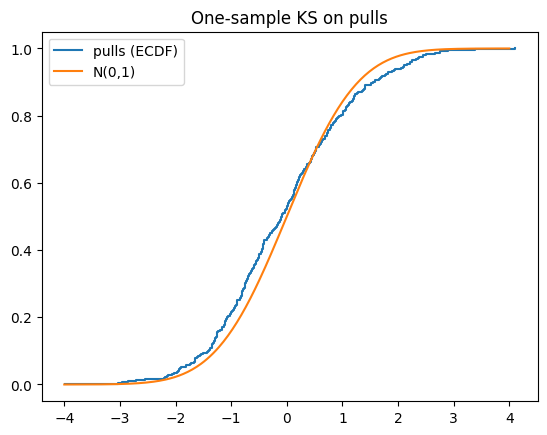

In [9]:
pulls = rng.normal(0, 1.25, size=400)       # underestimated uncertainties
x = np.sort(pulls); n = len(x); F = stats.norm.cdf(x); i = np.arange(1, n + 1)
D = max(np.max(i / n - F), np.max(F - (i - 1) / n))
print(f"manual: D = {D:.4f}")
print("scipy :", stats.kstest(pulls, "norm"))
print(f"pull std = {pulls.std(ddof=1):.3f}")
print("t-test on the mean (blind to the width problem):", stats.ttest_1samp(pulls, 0.0))

xs = np.linspace(-4, 4, 300)
plt.step(x, i / n, where="post", label="pulls (ECDF)"); plt.plot(xs, stats.norm.cdf(xs), label="N(0,1)")
plt.legend(); plt.title("One-sample KS on pulls"); plt.show()

## **3b. Data vs Monte Carlo shape (two-sample)**

 --- two-sample: same distribution?  
 Same mean and variance, different shape (Gaussian vs uniform)

KS two-sample : KstestResult(statistic=np.float64(0.094), pvalue=np.float64(0.02406614705241275), statistic_location=np.float64(0.7140433736571974), statistic_sign=np.int8(1))
t-test (means): TtestResult(statistic=np.float64(-1.066963282384261), pvalue=np.float64(0.2862464490703049), df=np.float64(997.9999893500799))


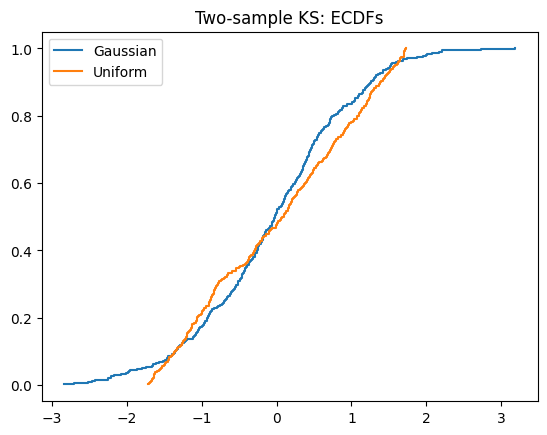

In [10]:
# --- two-sample: same distribution?  Same mean and variance, different shape (Gaussian vs uniform)
s1 = rng.normal(0, 1, size=500)
s2 = rng.uniform(-np.sqrt(3), np.sqrt(3), size=500)
print("KS two-sample :", stats.ks_2samp(s1, s2))
print("t-test (means):", stats.ttest_ind(s1, s2, equal_var=False))

for s, lab in [(s1, "Gaussian"), (s2, "Uniform")]:
    xs_ = np.sort(s)
    plt.step(xs_, np.arange(1, len(xs_) + 1) / len(xs_), where="post", label=lab)
plt.legend(); plt.title("Two-sample KS: ECDFs"); plt.show()

---
# **4. Wald–Wolfowitz runs test**

A **run** is a maximal block of identical symbols. For $n_1$ and $n_2$ symbols of the two kinds,

$$\mu_R=\frac{2n_1n_2}{n_1+n_2}+1,\qquad \sigma_R^2=\frac{2n_1n_2(2n_1n_2-n_1-n_2)}{(n_1+n_2)^2(n_1+n_2-1)},\qquad Z=\frac{R-\mu_R}{\sigma_R}$$

Too **few** runs: clustering (trend, systematic shape discrepancy). Too **many**: alternation.
The χ² only looks at the *size* of the residuals; the runs test looks at their **ordering**, so it catches a systematic
shape mismatch that still gives an acceptable χ².

In [11]:
def count_runs(labels):
    labels = np.asarray(labels)
    return 1 + np.count_nonzero(labels[1:] != labels[:-1])

def runs_z_test(labels, alternative="two-sided"):
    labels = np.asarray(labels)
    n1 = np.sum(labels == labels[0]); n2 = len(labels) - n1; N = n1 + n2
    R = count_runs(labels)
    mu = 2 * n1 * n2 / N + 1
    var = 2 * n1 * n2 * (2 * n1 * n2 - N) / (N**2 * (N - 1))
    z = (R - mu) / np.sqrt(var)
    p = {"two-sided": 2 * stats.norm.sf(abs(z)), "less": stats.norm.cdf(z), "greater": stats.norm.sf(z)}[alternative]
    return R, mu, z, p

# sanity check on a tiny example
print("runs in '++--++++---+-+-++--++++---+-+-+-++++--+-+--+':", count_runs(list("++--++++---+-+-++--++++---+-+-+-++++--+-+--+")))
print("Run Test :", runs_z_test(list("++--++++---+-+-++--++++---+-+-+-++++--+-+--+")))

runs in '++--++++---+-+-++--++++---+-+-+-++++--+-+--+': 25
Run Test : (np.int64(25), np.float64(22.818181818181817), np.float64(0.6713084401629864), np.float64(0.5020240589824061))


## **4a. Residuals of a fit to a mass-like spectrum**
The true spectrum is a falling exponential, but we fit a **straight line** (weighted by $1/\sqrt{O}$). The residual
signs come in long runs. A correct exponential fit gives randomly alternating signs.

linear (wrong)      : chi2/ndf = 29.37, runs =  3 (expect 20.6), z = -5.76, p = 8.651e-09 -> reject H0 at alpha = 0.05
exponential (right) : chi2/ndf =  0.72, runs = 20 (expect 20.9), z = -0.31, p = 0.7603 -> cannot reject H0 at alpha = 0.05


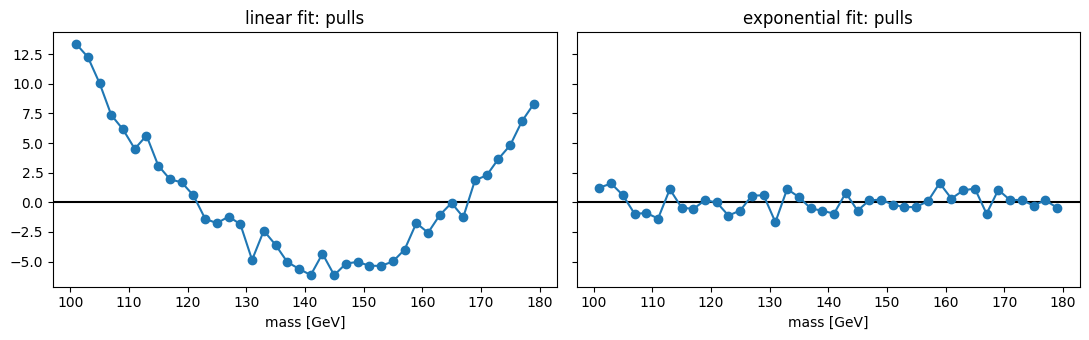

In [12]:
m = np.arange(101, 181, 2.0)                               # 40 bins
O = rng.poisson(1500 * np.exp(-(m - 100) / 30))
w = 1 / np.sqrt(O)

lin = np.polyfit(m, O, 1, w=w)
res_lin = (O - np.polyval(lin, m)) / np.sqrt(O)
popt, _ = optimize.curve_fit(lambda x, a, l: a * np.exp(-(x - 100) / l), m, O, p0=(1000, 40), sigma=np.sqrt(O))
res_exp = (O - popt[0] * np.exp(-(m - 100) / popt[1])) / np.sqrt(O)

for name, r in [("linear (wrong)", res_lin), ("exponential (right)", res_exp)]:
    R, mu, z, p = runs_z_test(r > 0)
    print(f"{name:20s}: chi2/ndf = {np.sum(r**2)/(len(m)-2):5.2f}, runs = {R:2d} (expect {mu:.1f}), z = {z:5.2f}, {verdict(p)}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for a, r, t in zip(ax, [res_lin, res_exp], ["linear fit", "exponential fit"]):
    a.axhline(0, color="k"); a.plot(m, r, "o-"); a.set_title(t + ": pulls"); a.set_xlabel("mass [GeV]")
plt.tight_layout(); plt.show()

## **4b. Data-quality monitoring: is the efficiency stable over time?**
Label each run as above/below the median efficiency. A slow drift produces long runs (few runs).

In [13]:
runs = np.arange(60)
ntrk = 2000
eff_stable = rng.binomial(ntrk, 0.96, size=60) / ntrk
eff_drift  = rng.binomial(ntrk, 0.96 - 0.0005 * runs, size=60) / ntrk       # slow loss: 0.96 -> 0.93

for name, e in [("stable", eff_stable), ("drifting", eff_drift)]:
    R, mu, z, p = runs_z_test(e > np.median(e), alternative="less")
    print(f"{name:9s}: runs = {R:2d} (expect {mu:.1f}), z = {z:5.2f}, {verdict(p)}")

stable   : runs = 38 (expect 31.0), z =  1.82, p = 0.9658 -> cannot reject H0 at alpha = 0.05
drifting : runs = 14 (expect 31.0), z = -4.43, p = 4.776e-06 -> reject H0 at alpha = 0.05


## **4c. Two-sample use**
Pool and sort two samples, label each point by origin, count runs; use the "too few runs" alternative. It reacts to *any* difference
(location or spread) but has low power; KS is usually preferred for this purpose.
If both samples come from the same distribution the labels are well mixed (many runs). If they differ (in location or spread) the labels cluster (few runs), so we use the one-sided "too few runs" alternative.

Below: same mean, different resolution.

In [14]:
def ww_two_sample(a, b):
    v = np.concatenate([a, b]); lab = np.concatenate([np.zeros(len(a)), np.ones(len(b))])
    return runs_z_test(lab[np.argsort(v, kind="stable")], alternative="less")

a = rng.normal(0, 1.0, 30); b = rng.normal(0, 3.0, 30)          # same mean, 3x worse resolution
R, mu, z, p = ww_two_sample(a, b)
print(f"Wald-Wolfowitz: R = {R}, E[R] = {mu:.1f}, {verdict(p)}   <- low power: KS does better here")
print("Welch t-test  :", stats.ttest_ind(a, b, equal_var=False))
print("KS            :", stats.ks_2samp(a, b))

Wald-Wolfowitz: R = 21, E[R] = 31.0, p = 0.004605 -> reject H0 at alpha = 0.05   <- low power: KS does better here
Welch t-test  : TtestResult(statistic=np.float64(1.8236605306037657), pvalue=np.float64(0.07593768397305564), df=np.float64(38.67868683590731))
KS            : KstestResult(statistic=np.float64(0.4), pvalue=np.float64(0.015643390496754332), statistic_location=np.float64(-2.1617152331332554), statistic_sign=np.int8(-1))


---
# **5. F-test**

## **5a. Comparing two resolutions (ratio of variances)**
$F=s_1^2/s_2^2\sim F_{n_1-1,n_2-1}$ under $H_0:\sigma_1=\sigma_2$.
**Very sensitive to non-Gaussian tails** (much more than the t-test) which detector response distributions nearly always have, so check it by toy MC. For non-normal data prefer Levene's or Brown–Forsythe's test (stats.levene).

In [15]:
def f_test_var(a, b):
    F = a.var(ddof=1) / b.var(ddof=1); d1, d2 = len(a) - 1, len(b) - 1
    return F, d1, d2, 2 * min(stats.f.cdf(F, d1, d2), stats.f.sf(F, d1, d2))

# relative pT resolution of two tracking algorithms on 40 and 60 events (Gaussian response)
algA = rng.normal(0, 0.020, 40); algB = rng.normal(0, 0.027, 60)
F, d1, d2, p = f_test_var(algA, algB)
print(f"F = {F:.3f} ({d1},{d2}) dof, {verdict(p)}")
print("Levene (robust):", stats.levene(algA, algB))

# Type-I error check: equal sigma, Gaussian vs heavy-tailed (Student t, 3 dof, scaled to unit variance)
def false_rate(gen, ntoy=3000, n=30):
    return np.mean([f_test_var(gen(n), gen(n))[3] < ALPHA for _ in range(ntoy)])

print(f"\nfalse-rejection rate, Gaussian tails    : {false_rate(lambda n: rng.normal(0, 1, n)):.3f}  (nominal 0.05)")
print(f"false-rejection rate, heavy (t, 3 dof)  : {false_rate(lambda n: rng.standard_t(3, n) / np.sqrt(3)):.3f}")

F = 0.296 (39,59) dof, p = 0.0001088 -> reject H0 at alpha = 0.05
Levene (robust): LeveneResult(statistic=np.float64(5.873224403632782), pvalue=np.float64(0.017207607826723988))

false-rejection rate, Gaussian tails    : 0.050  (nominal 0.05)
false-rejection rate, heavy (t, 3 dof)  : 0.329


## **5b. Nested models: how many polynomial terms does the background need?**
Typical in resonance searches: fit the background with a polynomial of degree $d$ and ask whether degree $d+1$ is justified.
For Gaussian-like errors (high counts):

$$F=\frac{(\chi^2_d-\chi^2_{d+1})/1}{\chi^2_{d+1}/(N-p_{d+1})}\;\sim\;F_{1,\,N-p_{d+1}},\qquad p_{d+1}=d+2$$

# **Example:** 50 bins of a smooth falling spectrum between 110 and 160 GeV.

In [16]:
mm = np.linspace(110, 160, 50)
x = (mm - 135) / 25                                   # rescale for numerical stability
O = rng.poisson(6000 * np.exp(-(mm - 110) / 25))
sig = np.sqrt(O)
N = len(mm)

def chi2_poly(deg):
    c = np.polyfit(x, O, deg, w=1 / sig)
    return np.sum(((O - np.polyval(c, x)) / sig) ** 2)

print(f"{'deg':>3} {'chi2':>8} {'ndf':>4} | {'F':>7} {'p(deg vs deg-1)':>16}")
prev = chi2_poly(0)
print(f"{0:>3} {prev:8.1f} {N-1:>4} |")
for deg in range(1, 7):
    c2 = chi2_poly(deg)
    F = (prev - c2) / (c2 / (N - (deg + 1)))
    print(f"{deg:>3} {c2:8.1f} {N-deg-1:>4} | {F:7.2f} {stats.f.sf(F, 1, N-deg-1):16.4f}")
    prev = c2

deg     chi2  ndf |       F  p(deg vs deg-1)
  0  38072.7   49 |
  1   2784.9   48 |  608.21           0.0000
  2    125.0   47 | 1000.51           0.0000
  3     56.6   46 |   55.62           0.0000
  4     56.5   45 |    0.04           0.8354
  5     56.5   44 |    0.04           0.8486
  6     55.8   43 |    0.49           0.4857


Choose the lowest degree after which the next term is no longer significant. With low counts replace this by a
**likelihood-ratio test** (Wilks: $-2\Delta\ln L\sim\chi^2_{\Delta p}$); and remember the real danger in a bump search is a *biased* background
model, which is better checked with a spurious-signal test.

---
# **6. Bayesian hypothesis testing**

$$\mathrm{BF}_{01}=\frac{P(D\mid H_0)}{P(D\mid H_1)},\qquad \text{posterior odds}=\mathrm{BF}_{01}\times\text{prior odds}$$

Marginal likelihoods average the likelihood over the prior of each hypothesis's parameters, which gives an automatic Occam penalty.
BF can support $H_0$, but depends on the prior under $H_1$, so always show the sensitivity.

## **6a. Counting experiment: p-value and Bayes factor for a signal**
Observed $n=25$ events with expected background $b=12$ (known). $H_0$: $s=0$. $H_1$: $s>0$ with a flat prior on $[0,s_\text{max}]$.

* Frequentist: $p=P(N\ge n\mid b)$, converted to $Z$.
* Bayesian: $P(n\mid H_1)=\dfrac1{s_\text{max}}\displaystyle\int_0^{s_\text{max}}\mathrm{Pois}(n;b+s)\,ds=\dfrac{\Gamma\text{-cdf}(b+s_\text{max};n+1)-\Gamma\text{-cdf}(b;n+1)}{s_\text{max}}$

p-value = 6.86e-04 -> Z = 3.20 sigma

prior sensitivity (flat prior on s in [0, smax]):
  smax =     10: BF10 =     58.91
  smax =     30: BF10 =     87.90
  smax =    100: BF10 =     26.46
  smax =   1000: BF10 =      2.65
  smax =  10000: BF10 =      0.26

posterior (flat prior): mode = 13.0, 68% central interval = [8.9, 19.0]


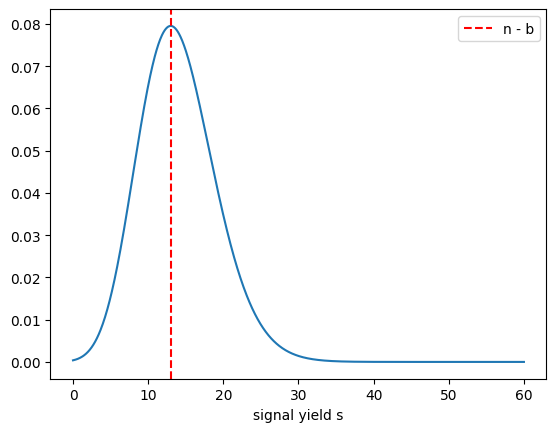

In [19]:
n_obs, b = 25, 12.0

p_val = stats.poisson.sf(n_obs - 1, b)                # P(N >= n_obs | b)
print(f"p-value = {p_val:.2e} -> Z = {p_to_Z(p_val):.2f} sigma")

def bf10_counting(n, b, smax):
    m1 = (stats.gamma.cdf(b + smax, n + 1) - stats.gamma.cdf(b, n + 1)) / smax
    return m1 / stats.poisson.pmf(n, b)

print("\nprior sensitivity (flat prior on s in [0, smax]):")
for smax in [10, 30, 100, 1000, 10000]:
    print(f"  smax = {smax:6d}: BF10 = {bf10_counting(n_obs, b, smax):9.2f}")

# posterior for s (flat prior up to 100)
s = np.linspace(0, 60, 1000)
post = stats.poisson.pmf(n_obs, b + s); post /= np.trapezoid(post, s)
cdf = np.cumsum(post) * (s[1] - s[0])
print(f"\nposterior (flat prior): mode = {s[np.argmax(post)]:.1f}, 68% central interval = [{s[np.searchsorted(cdf, .16)]:.1f}, {s[np.searchsorted(cdf, .84)]:.1f}]")
plt.plot(s, post); plt.axvline(n_obs - b, color="r", ls="--", label="n - b"); plt.xlabel("signal yield s"); plt.legend(); plt.show()

The p-value says "3σ-ish". The Bayes factor depends on how wide a prior we give the signal: an enormous $s_\text{max}$ ("the signal could be
anywhere up to 10000 events") is penalised by the Occam factor. Always report BF with the prior choice.

## **6b. Fixed p-value, growing statistics (Jeffreys–Lindley)**
Measure a small mass shift $\Delta$ with $n$ events (per-event resolution $\sigma$): $\bar x\sim N(\Delta,\sigma^2/n)$.
$H_0:\Delta=0$ vs $H_1:\Delta\sim N(0,\tau^2)$. The Bayes factor is analytic:
$$\mathrm{BF}_{10}=\frac{N(\bar x;0,\tau^2+\sigma^2/n)}{N(\bar x;0,\sigma^2/n)}$$

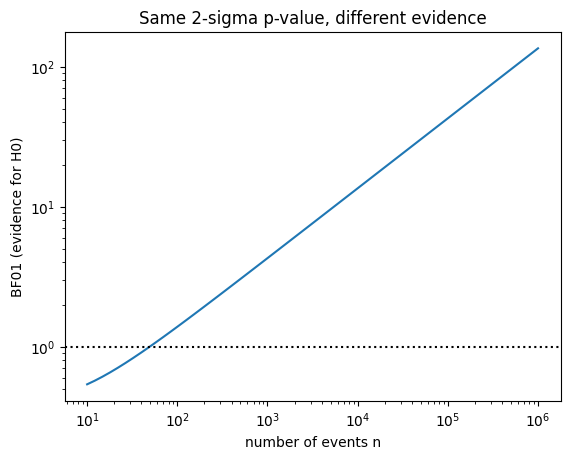

n =        10: p = 0.046, BF01 = 0.54
n =       100: p = 0.046, BF01 = 1.39
n =    10,000: p = 0.046, BF01 = 13.54
n = 1,000,000: p = 0.046, BF01 = 135.34


In [20]:
def bf10_gauss(xbar, n, sigma, tau):
    se2 = sigma**2 / n
    return stats.norm.pdf(xbar, 0, np.sqrt(tau**2 + se2)) / stats.norm.pdf(xbar, 0, np.sqrt(se2))

sigma, tau, z = 1.0, 1.0, 2.0                  # fixed 2-sigma result (p = 0.046)
ns = np.logspace(1, 6, 60)
bf01 = np.array([1 / bf10_gauss(z * sigma / np.sqrt(n), n, sigma, tau) for n in ns])

plt.loglog(ns, bf01); plt.axhline(1, color="k", ls=":")
plt.xlabel("number of events n"); plt.ylabel("BF01 (evidence for H0)")
plt.title("Same 2-sigma p-value, different evidence"); plt.show()

for n in [10, 100, 10_000, 1_000_000]:
    print(f"n = {n:>9,}: p = {2*Z_to_p(z):.3f}, BF01 = {1/bf10_gauss(z*sigma/np.sqrt(n), n, sigma, tau):.2f}")

---
# **7. Look-elsewhere effect: local vs global significance**

If you scan many mass bins for a bump, the chance that **some** bin fluctuates high is much larger than for one pre-defined bin.
The **local** p-value is for the bin where the excess appears; the **global** p-value accounts for the whole scan.
It is estimated with toy MC: generate background-only experiments and look at the **maximum** local significance.

 local Z    local p   global p  global Z
     3.0   1.35e-03   7.05e-02      1.47
     3.5   2.33e-04   1.09e-02      2.29
     4.0   3.17e-05   1.85e-03      2.90


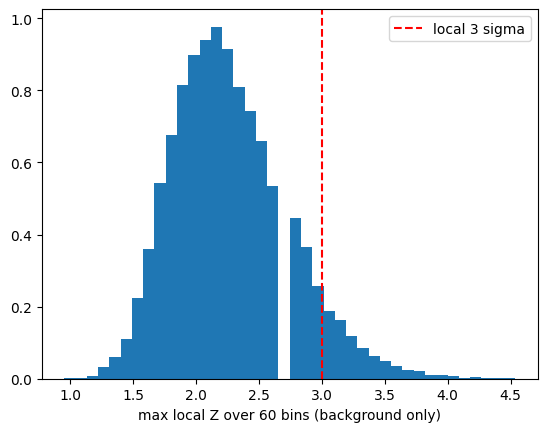

In [21]:
nbins, b, ntoys = 60, 100.0, 20000
toys = rng.poisson(b, size=(ntoys, nbins))
p_local = stats.poisson.sf(toys - 1, b)                   # per-bin local p-values
maxZ = p_to_Z(p_local.min(axis=1))                        # most significant bin in each toy

print(f"{'local Z':>8} {'local p':>10} {'global p':>10} {'global Z':>9}")
for Zloc in [3.0, 3.5, 4.0]:
    pg = np.mean(maxZ >= Zloc)
    print(f"{Zloc:8.1f} {Z_to_p(Zloc):10.2e} {pg:10.2e} {p_to_Z(pg) if pg > 0 else float('inf'):9.2f}")

plt.hist(maxZ, bins=40, density=True); plt.xlabel("max local Z over 60 bins (background only)")
plt.axvline(3, color="r", ls="--", label="local 3 sigma"); plt.legend(); plt.show()

A local 3σ excess somewhere in a 60-bin scan is not remarkable: the trials factor is about the number of independent bins.
This is why discovery claims use the 5σ threshold.

---
## Summary

| Test | Typical use | Statistic / null distribution | Watch out for |
|---|---|---|---|
| One-sample t | calibration constant vs reference | $t_{n-1}$ | small samples only; for known σ use $z$ |
| Two-sample t (Welch) | two modules / settings | $t_\nu$ | independent samples |
| Paired t | before/after on the same objects | $t_{n-1}$ on differences | genuine pairing |
| χ² (Pearson / LR) | histogram vs model | $\chi^2_{N-m}$ | low counts: use LR χ² and toys; subtract fitted parameters |
| χ² independence | channels vs periods | $\chi^2_{(r-1)(c-1)}$ | $E_{ij}\gtrsim5$ |
| Kolmogorov–Smirnov | pulls, data vs MC unbinned | $D=\sup\lvert F_n-F\rvert$ | no fitted parameters; no weights in scipy |
| Wald–Wolfowitz | fit residuals, DQ stability | $Z$ from number of runs | low power; ties |
| F (variances) | compare resolutions | $F_{n_1-1,n_2-1}$ | heavy tails break it |
| F (nested) | background polynomial degree | $F_{1,N-p}$ | high counts; otherwise use LR test |
| Bayes factor | efficiencies, counting, hypotheses | $P(D\mid H_0)/P(D\mid H_1)$ | prior dependence under $H_1$ |
| Toy MC (LEE) | local → global significance | MC distribution of max Z | trials factor |

## Exercises
1. In 2a, reduce `N` in `true_par` to 500 (most tail bins then have 0–2 events). Which statistic, Pearson or likelihood-ratio, keeps a correct 5% false-rejection rate in the toy test?
2. Generate 8 test-beam runs (n = 8) in 1a with true mean equal to the reference. Repeat 5000 times: what fraction of t-tests reject at 5%? What if you use a $z$-test with σ estimated from the sample?
3. In 3b, give the MC events weights (e.g. weights increasing with $p_T$). Why can't you use `ks_2samp` directly, and how would you build a weighted KS statistic and calibrate its p-value with toys?
4. In 4a, add a small Gaussian bump to the data and fit only the smooth background. How do χ²/ndf and the runs test compare in sensitivity?
5. In 5b, change the true spectrum normalisation from 6000 to 300. Does the F-test still select the same polynomial degree? Replace it by a likelihood-ratio test using Poisson fits.
6. In 6b, vary the observed count $n$ from 12 to 40 and plot $Z$ and $\log\mathrm{BF}_{10}$ (for $s_\text{max}=100$) on the same axes.
7. In 7, change the number of bins to 10, 60, 300 and plot the global p-value of a local 3σ excess against the number of bins.